<a href="https://colab.research.google.com/github/govardhansnair/Monte-Carlo-Option-Pricing/blob/main/03_Live_Monte_Carlo_Project_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

LIVE MONTE CARLO OPTION PRICING
Ticker: AAPL
Market data date: 2026-11-20 00:00:00-05:00
Stock Price: $342.5600
Strike Price: $100.0000
Volatility: 25.00%
Risk-free Rate: 0.05%
Time to Expiry: 20 days
Simulations: 100,000

OPTION PRICES
       Method     Call  Put
  Monte Carlo 242.6204  0.0
Black-Scholes 242.5627  0.0

STANDARD ERROR AND CONFIDENCE INTERVAL
Call SE: 0.06347
Call 95% CI: (242.4960, 242.7448)
Put SE: 0.00000
Put 95% CI: (0.0000, 0.0000)

CALL GREEKS
Delta: 1.000168
Gamma: 0.000000
Vega (1%): 0.002314
Theta (day): -0.001584
Rho (1%): 0.054793

PUT GREEKS
Delta: 0.000000
Gamma: 0.000000
Vega (1%): 0.000000
Theta (day): -0.000000
Rho (1%): 0.000000

ANTITHETIC VARIATES
Standard MC: 242.62044
Antithetic MC: 242.56435
Standard Error: 0.06347
Antithetic SE: 0.00371


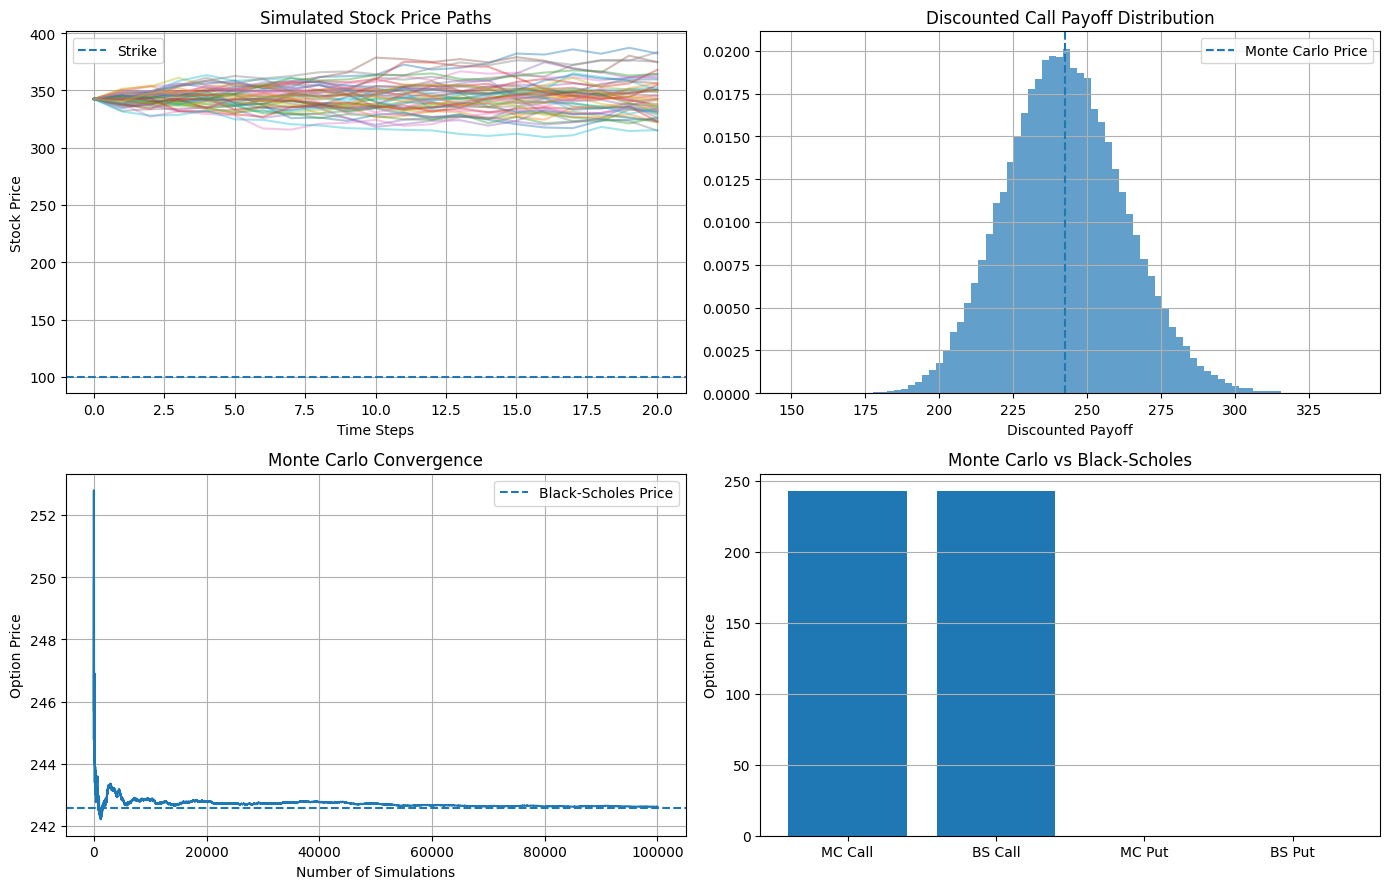


Next update in 60 seconds.


In [ ]:

import time
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm
from IPython.display import clear_output

# INPUTS

ticker = input("Enter stock ticker (e.g. AAPL): ").strip().upper()
K = float(input("Enter strike price: "))
days = int(input("Enter days to expiry: "))
r = float(input("Enter risk-free rate in %: ")) / 100

N = 100000
refresh_time = 60
TRADING_DAYS = 252

if not ticker or K <= 0 or days <= 0:
    raise ValueError("Enter valid inputs.")

# BLACK-SCHOLES MODEL

def black_scholes(S, K, r, sigma, T, option):

    d1 = (np.log(S/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)

    if option == "call":
        return S*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)

    else:
        return K*np.exp(-r*T)*norm.cdf(-d2) - S*norm.cdf(-d1)


# MONTE CARLO MODEL

def monte_carlo(S, K, r, sigma, T, Z, option):

    ST = S * np.exp((r - 0.5*sigma**2)*T+ sigma*np.sqrt(T)*Z)

    if option == "call":
        payoff = np.maximum(ST-K, 0)

    else:
        payoff = np.maximum(K-ST, 0)

    discounted_payoff = np.exp(-r*T)*payoff

    price = np.mean(discounted_payoff)

    SE = np.std(discounted_payoff, ddof=1)/np.sqrt(len(Z))

    CI_lower = price - 1.96*SE
    CI_upper = price + 1.96*SE

    return price, SE, CI_lower, CI_upper, discounted_payoff


# GREEKS

def calculate_greeks(S, K, r, sigma, T, Z, option):

    def price(s, rate, vol, expiry):

        return monte_carlo(s, K, rate, vol, expiry, Z, option)[0]

    h = S*0.001
    dv = 0.001
    dr = 0.0001
    dt = min(1/365, T/2)

    V = price(S, r, sigma, T)

    delta = (price(S+h, r, sigma, T)- price(S-h, r, sigma, T))/(2*h)

    gamma = (price(S+h, r, sigma, T)- 2*V+ price(S-h, r, sigma, T))/(h**2)

    vega = (price(S, r, sigma+dv, T)- price(S, r, sigma-dv, T))/(2*dv*100)

    rho = (price(S, r+dr, sigma, T)- price(S, r-dr, sigma, T))/(2*dr*100)

    theta = -(price(S, r, sigma, T+dt)- price(S, r, sigma, T-dt))/(2*dt*365)

    return {
        "Delta": delta,
        "Gamma": gamma,
        "Vega (1%)": vega,
        "Theta (day)": theta,
        "Rho (1%)": rho
    }


# LIVE UPDATE LOOP

print("Starting live Monte Carlo model...")
print("Press interrupt to stop.")

while True:

    try:

        # Download Yahoo Finance data

        stock = yf.Ticker(ticker)

        history = stock.history(
            period="1y",
            interval="1d",
            auto_adjust=True
        )

        if len(history) < 30:
            raise ValueError("Insufficient Yahoo Finance data.")

        S = float(history["Close"].dropna().iloc[-1])

        # Calculate historical volatility

        returns = np.log(
            history["Close"]/history["Close"].shift(1)
        ).dropna()

        sigma = returns.std()*np.sqrt(TRADING_DAYS)

        T = days/365

        if not np.isfinite(S) or not np.isfinite(sigma) or sigma <= 0:
            raise ValueError("Invalid market price or volatility.")

        # Generate random numbers

        Z = np.random.normal(0, 1, N)

        # Monte Carlo prices

        call_MC, call_SE, call_low, call_high, call_payoff = (
            monte_carlo(S, K, r, sigma, T, Z, "call")
        )

        put_MC, put_SE, put_low, put_high, put_payoff = (
            monte_carlo(S, K, r, sigma, T, Z, "put")
        )

        # Black-Scholes prices

        call_BS = black_scholes(S, K, r, sigma, T, "call")

        put_BS = black_scholes(S, K, r, sigma, T, "put")

        # Greeks

        call_greeks = calculate_greeks(
            S, K, r, sigma, T, Z, "call"
        )

        put_greeks = calculate_greeks(
            S, K, r, sigma, T, Z, "put"
        )

        # ANTITHETIC VARIATES

        Z_half = np.random.normal(0, 1, N//2)

        drift = (r-0.5*sigma**2)*T
        diffusion = sigma*np.sqrt(T)

        ST_positive = S*np.exp(drift+diffusion*Z_half)
        ST_negative = S*np.exp(drift-diffusion*Z_half)

        paired_payoff = 0.5*np.exp(-r*T)*(
            np.maximum(ST_positive-K, 0)
            + np.maximum(ST_negative-K, 0)
        )

        anti_price = np.mean(paired_payoff)

        anti_SE = (
            np.std(paired_payoff, ddof=1)
            /np.sqrt(N//2)
        )

        # DISPLAY RESULTS

        clear_output(wait=True)

        print("="*55)
        print("LIVE MONTE CARLO OPTION PRICING")
        print("="*55)

        print("Ticker:", ticker)
        print("Market data date:", history.index[-1])
        print(f"Stock Price: ${S:.4f}")
        print(f"Strike Price: ${K:.4f}")
        print(f"Volatility: {sigma:.2%}")
        print(f"Risk-free Rate: {r:.2%}")
        print(f"Time to Expiry: {days} days")
        print(f"Simulations: {N:,}")

        # Option prices

        print("\nOPTION PRICES")

        results = pd.DataFrame({
            "Method": ["Monte Carlo", "Black-Scholes"],
            "Call": [call_MC, call_BS],
            "Put": [put_MC, put_BS]
        })

        print(results.round(4).to_string(index=False))

        # Statistical accuracy

        print("\nSTANDARD ERROR AND CONFIDENCE INTERVAL")

        print(f"Call SE: {call_SE:.5f}")
        print(f"Call 95% CI: ({call_low:.4f}, {call_high:.4f})")

        print(f"Put SE: {put_SE:.5f}")
        print(f"Put 95% CI: ({put_low:.4f}, {put_high:.4f})")

        # Greeks

        print("\nCALL GREEKS")

        for name, value in call_greeks.items():
            print(f"{name}: {value:.6f}")

        print("\nPUT GREEKS")

        for name, value in put_greeks.items():
            print(f"{name}: {value:.6f}")

        # Antithetic results

        print("\nANTITHETIC VARIATES")

        print(f"Standard MC: {call_MC:.5f}")
        print(f"Antithetic MC: {anti_price:.5f}")
        print(f"Standard Error: {call_SE:.5f}")
        print(f"Antithetic SE: {anti_SE:.5f}")

        # VISUALISATIONS

        fig, axes = plt.subplots(2, 2, figsize=(14, 9))

        # 1. Stock price simulations

        steps = max(2, min(days, 252))
        dt = T/steps

        Z_paths = np.random.normal(0, 1, (50, steps))

        paths = np.zeros((50, steps+1))
        paths[:, 0] = S

        for t in range(steps):

            paths[:, t+1] = paths[:, t]*np.exp(
                (r-0.5*sigma**2)*dt
                + sigma*np.sqrt(dt)*Z_paths[:, t]
            )

        for path in paths:
            axes[0, 0].plot(path, alpha=0.4)

        axes[0, 0].axhline(K, linestyle="--", label="Strike")

        axes[0, 0].set_title("Simulated Stock Price Paths")
        axes[0, 0].set_xlabel("Time Steps")
        axes[0, 0].set_ylabel("Stock Price")
        axes[0, 0].legend()
        axes[0, 0].grid()

        # 2. Payoff distribution

        axes[0, 1].hist(
            call_payoff,
            bins=80,
            density=True,
            alpha=0.7
        )

        axes[0, 1].axvline(
            call_MC,
            linestyle="--",
            label="Monte Carlo Price"
        )

        axes[0, 1].set_title("Discounted Call Payoff Distribution")
        axes[0, 1].set_xlabel("Discounted Payoff")
        axes[0, 1].legend()
        axes[0, 1].grid()

        # 3. Monte Carlo convergence

        running_average = (
            np.cumsum(call_payoff)
            /np.arange(1, N+1)
        )

        axes[1, 0].plot(running_average)

        axes[1, 0].axhline(
            call_BS,
            linestyle="--",
            label="Black-Scholes Price"
        )

        axes[1, 0].set_title("Monte Carlo Convergence")
        axes[1, 0].set_xlabel("Number of Simulations")
        axes[1, 0].set_ylabel("Option Price")
        axes[1, 0].legend()
        axes[1, 0].grid()

        # 4. Pricing comparison

        axes[1, 1].bar(
            ["MC Call", "BS Call", "MC Put", "BS Put"],
            [call_MC, call_BS, put_MC, put_BS]
        )

        axes[1, 1].set_title("Monte Carlo vs Black-Scholes")
        axes[1, 1].set_ylabel("Option Price")
        axes[1, 1].grid(axis="y")

        plt.tight_layout()
        plt.show()

        print(f"\nNext update in {refresh_time} seconds.")

        time.sleep(refresh_time)

    except KeyboardInterrupt:

        print("\nLive model stopped.")
        break

    except Exception as error:

        clear_output(wait=True)

        print("Update error:", error)
        print(f"Retrying in {refresh_time} seconds.")

        time.sleep(refresh_time)
